# Robustness to nuisance parameters

How the albedo bias, $\sigma_{A_B}$ and the expected evidence change when the fit also marginalises over the transit geometry and ellipsoidal variations. Each nuisance is one more column of a linear least-squares problem around the noiseless $A_B$-only fit (`hyperphase.bias.nuisance`; whitened units, a Gaussian prior as a penalty row):
$$\delta = \arg\min\ \lVert r_\perp - X\delta\rVert^2 + \sum_\nu (\delta_\nu/\sigma_{p,\nu})^2, \qquad {\rm Cov} = (X^{\sf T}X + \Lambda)^{-1},$$
with $r_\perp$ the residual of the $A_B$-only fit and $X = [j_A, j_{\nu_1}, \dots]$ the whitened derivatives. If the extended-source model carries the same nuisances, $\langle\ln B\rangle \approx \chi^{2\prime}_{\min}/2$.

The nuisances are the **geometry** ($a/R_\star$, $R_p/R_\star$ and $b$ or $i$, with the priors of each planet's source), the **stellar ellipsoidal variation** ($-\cos 4\pi\phi$; one amplitude with a physical prior, `stellar_shared`, or a free one per band, `stellar`) and the **planetary tidal deformation** (Akinsanmi et al. 2024; zero during the occultation), in the headline rows with a flat prior on the Love number over its physical range $1 \leq h_2 \leq 2.5$.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.model import ConstantBandAlbedo, FittingConfig, model_pcurve
from hyperphase.bands import detector_label, filter_lambda, filter_loc, JWST_BANDS
from hyperphase.bias.detectors import detectors, is_detector_set, retrieval_cfg
from hyperphase.bias.evidence import evidence_residual
from hyperphase.bias.nuisance import (DEFORMATION_H2_RANGE, deformation_limits, deformation_prior, ELLIPSOIDAL_G_RANGE, ellipsoidal_prior,
                                      ELLIPSOIDAL_U_RANGE, M_EARTH_SUN, nuisance_both_fits, nuisance_fit_nonlinear, nuisance_problem, nuisance_solve,
                                      nuisance_table, nuisance_uniform, stellar_shared_column)
from hyperphase.parallel import pmap
from hyperphase.plotting.style import AXIS, C_HI, C_NAIVE, C_REDIST, INK, INK_2, instrument_label, MUTED, set_plot_style
from hyperphase.targets import hi_planets_by_name
from hyperphase.paper import DEFORMATION_H2_TRUE, GEOMETRY_PARAMS, GEOMETRY_SIGMA, PLANET_MASSES

set_plot_style()

In [2]:
# Baseline settings (hyperphase/defaults.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)
u, u_bol = DEFAULT_U, DEFAULT_U_BOL
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# Planets and modes: MIRI/LRS, the joint NIRSpec fit, and all three detectors jointly (a tuple = one joint fit: shared A_B, a baseline per detector)
LRS, NRS1, NRS2 = "MIRI/LRS", *JWST_BANDS[:2]
MODES = {"joint NIRSpec": (NRS1, NRS2), "MIRI/LRS": LRS, "NIRSpec + LRS": (NRS1, NRS2, LRS)}   # wavelength order (tables, figure lines, figure columns)
PLANETS = ("TOI-2431 b", "K2-141 b")

# The published uncertainties of the reference planets are defined once, with their sources, in hyperphase/paper.py: GEOMETRY_SIGMA (Gaussian priors, 1 sigma, on the parameters each source
# FITTED, centred on the adopted values; independent, correlations ignored), GEOMETRY_PARAMS (that parametrisation: (a/R*, Rp/R*, b) for TOI-2431 b, whose source fitted b and derived i;
# (a/R*, Rp/R*, i) for K2-141 b), PLANET_MASSES and the (u, g) bracket of the stellar ellipsoidal term. They are exactly the priors of the free-geometry dynesty runs
# (the free-geometry runs of retrievals/paper_runs/make_runs.py), so the "+ all geometry" row is the prediction for those runs.
PRIORS = {name: dict(GEOMETRY_SIGMA[name]) for name in PLANETS}       # a copy per planet: the prior of the shared stellar amplitude is added to it below
INCLINATION = {name: GEOMETRY_PARAMS[name][2] for name in PLANETS}   # the third geometry parameter, as the planet's source fitted it ("b" or "incl")

# The stellar ellipsoidal term (section 3). Its relative amplitude A_ell = alpha_ell (M_p / M_star) (R_star / a)^3 sin^2 i is set by measured quantities and depends on the band only
# through alpha_ell(u, g), so the realistic nuisance is ONE amplitude for all bands ("stellar_shared") with the prior these imply; one free amplitude per band ("stellar") is the worst case.
MASSES = PLANET_MASSES                                        # M_p [M_E] and its 1 sigma, M_star [M_sun] and its 1 sigma
U_RANGE, G_RANGE = ELLIPSOIDAL_U_RANGE, ELLIPSOIDAL_G_RANGE   # bracket of the linear limb-darkening and gravity-darkening coefficients in the infrared (not tabulated values, see section 3)
STELLAR_RATIOS = None   # alpha_ell of each band relative to the others, {band: ratio}; None = achromatic. Physically within ~10 % across these bands (section 3 varies it by +-15 %)

def mass_ratio(name):
    """M_p / M_star of a planet and its fractional 1-sigma error."""
    Mp, sMp, Ms, sMs = MASSES[name]
    return Mp * M_EARTH_SUN / Ms, float(np.hypot(sMp / Mp, sMs / Ms))

ELLIPSOIDAL = {name: ellipsoidal_prior(hi_planets_by_name(name), *mass_ratio(name), U_RANGE, G_RANGE, sig_a_rs=PRIORS[name]["a_rs"], sig_incl=PRIORS[name]["incl"]) for name in PLANETS}
for name in PLANETS: PRIORS[name]["stellar_shared"] = ELLIPSOIDAL[name]["sigma"]   # [ppm] the prior of the shared amplitude, centred on the truth (which has no ellipsoidal term)

# The planetary deformation of a planet with the Love number DEFORMATION_H2_TRUE. The headline rows give h2 a flat prior over DEFORMATION_H2_RANGE: LIMITS is the
# shift of the amplitude from its true value that this range allows (the `uniform` of nuisance_table and nuisance_both_fits). A free amplitude is a diagnostic only.
DEFORMATION = {name: deformation_prior(hi_planets_by_name(name), mass_ratio(name)[0]) for name in PLANETS}   # the amplitude of the planetary term over the Love-number range
LIMITS = {name: {"planetary": deformation_limits(hi_planets_by_name(name), mass_ratio(name)[0], DEFORMATION_H2_TRUE, DEFORMATION_H2_RANGE)} for name in PLANETS}
H2_RANGE = f"{DEFORMATION_H2_RANGE[0]:g} ≤ h₂ ≤ {DEFORMATION_H2_RANGE[1]:g}"   # for the row labels

# Rows of the table, per planet: which nuisances are free in addition to A_B and the baseline(s). The geometry follows the source's parametrisation: with b (TOI-2431 b), a/R*
# varies at fixed b ("a_rs|b", i follows); with i (K2-141 b), at fixed i. A row is a tuple of nuisances, or a dict with a flat bounded prior on one of them (posterior
# quantities, nuisance_uniform). The single-parameter and single-term rows and the free deformation are diagnostics (in tab only); FIGURE_ROWS are the headline rows.
GEOM = ("a_rs", "rp_rs", "incl")   # the finite-difference columns; b and a_rs|b follow from them by the chain rule (nuisance_problem)

def rows_of(name):
    third = INCLINATION[name]
    geom = ("a_rs|b" if third == "b" else "a_rs", "rp_rs", third)
    return {"fixed": (), "+ a/R*": geom[:1], "+ Rp/R*": ("rp_rs",), "+ b or i": (third,), "+ all geometry": geom,
            "+ stellar (physical)": ("stellar_shared",), "+ geometry + stellar (physical)": (*geom, "stellar_shared"), "+ stellar (free per band)": ("stellar",),
            "+ planetary (free amplitude)": ("planetary",), "+ geometry + planetary (free amplitude)": (*geom, "planetary"),
            f"+ geometry + planetary ({H2_RANGE})": dict(nuisances=(*geom, "planetary"), uniform=LIMITS[name])}

ROWS = {name: rows_of(name) for name in PLANETS}
FIGURE_ROWS = ["fixed", "+ all geometry", "+ geometry + stellar (physical)", "+ stellar (free per band)", f"+ geometry + planetary ({H2_RANGE})"]   # the headline rows (the tables of section 1 and the figure)
FIGURE_MODES = ["joint NIRSpec", "MIRI/LRS"]   # the paper's primary modes (figure); NIRSpec + LRS is in the tables

# Template cfg: band, planet and noise are replaced per case (retrieval_cfg)
l1, l2 = filter_lambda(LRS)
cfg = FittingConfig(planet=hi_planets_by_name(PLANETS[0]), filter_path=filter_loc(LRS), l1=l1, l2=l2, A_=A_model, sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)

## 1. The table

One linear problem per planet and mode (`nuisance_problem`), solved for each row of `ROWS` (`nuisance_table`): how much each nuisance widens $\sigma_{A_B}$, moves the bias and how much of $\chi^2_{\min}$ it absorbs. The deformation row gives $h_2$ a flat prior over its physical range, so its numbers are posterior quantities (the bias is the difference of the two models' posterior medians of $A_B$, `nuisance_uniform`); with a free amplitude, a diagnostic in `tab`, the fit can take deformations outside that range (section 6 compares the priors). Per planet, the first table gives $\sigma_{A_B}$, $\Delta A_B$, $|\Delta A_B|/\sigma_{A_B}$ and $\langle\ln B\rangle$ per mode; the second the shift of each geometry parameter in posterior $\sigma$ (shrinkage in brackets) and the fitted ellipsoidal amplitudes (stellar in ppm, planetary as the shift of $\delta$ from its true value; posterior mean and sd in the deformation row), which the truth does not contain. The tables show the headline rows `FIGURE_ROWS`; the tidy `tab` holds every row, including the single-parameter diagnostics. `+ all geometry` is the prediction for the free-geometry retrievals.

In [3]:
def case(name, mode):
    '''The nuisance problem of one planet in one mode: its own geometry and noise, the noiseless hyperillumination truth, every column.'''
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, **kw)

CASES = [(name, mode) for name in PLANETS for mode in MODES]
PROBLEMS = dict(zip(CASES, pmap(case, CASES)))
TABLES = {k: nuisance_table(p, A_B_true, ROWS[k[0]]) for k, p in PROBLEMS.items()}
tab = pd.concat([t.assign(planet=k[0], mode=k[1]) for k, t in TABLES.items()], ignore_index=True)   # tidy: one row per planet, mode and nuisance row

# Display, per planet and for the headline rows (FIGURE_ROWS; tab holds every row): the four key numbers per mode, then what the nuisances of each row do
HEAD = {"sigma_A_B": "σ_AB", "bias_A_B": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩"}
SHORT = {"a_rs": "a/R*", "a_rs|b": "a/R*", "rp_rs": "Rp/R*", "b": "b", "incl": "i", "planetary": "planetary"}

def solution(p, row):
    '''The A_B-only solution of one row: nuisance_solve, or for a row with a flat bounded prior its posterior (nuisance_uniform).'''
    return nuisance_uniform(p, A_B_true, row["nuisances"], row["uniform"])["fit"] if isinstance(row, dict) else nuisance_solve(p, row)

def nuisance_text(p, row, mode):
    '''The nuisances of one row in one line: the shift of each geometry parameter in posterior sigma and its sigma_post / sigma_prior, the fitted value +- sigma of each ellipsoidal amplitude.'''
    s, dets = solution(p, row), [detector_label(d) for d in detectors(MODES[mode])]
    parts = []
    for n in s["names"]:
        v, e, sh = s["delta"][n], s["sigma_post"][n], s["shrinkage"][n]
        if n in p["values"]: parts.append(f"{SHORT[n]} {v / e:+.2f}σ ({sh:.2f})")   # shift in posterior sigma (sigma_post / sigma_prior)
        elif n.startswith("stellar:"): parts.append(f"stellar {dets[int(n.split(':')[1]) - 1]} {v:.1f} ± {e:.1f} ppm")
        elif n == "stellar_shared": parts.append(f"stellar {v:.1f} ± {e:.1f} ppm (shrink {sh:.2f})")
        else: parts.append(f"{SHORT[n]} {v:.3f} ± {e:.3f}")
    return " · ".join(parts) or "-"

for name in PLANETS:
    summary = pd.concat({mode: TABLES[(name, mode)].set_index("row").loc[FIGURE_ROWS, list(HEAD)].rename(columns=HEAD) for mode in MODES}, axis=1)
    summary.index.name = None
    fits = ", ".join(f"{m} {PROBLEMS[(name, m)]['A_B_fit']:.3f}" for m in MODES)
    display(summary.style.format("{:.3g}").set_caption(f"{name}: σ_AB, bias ΔA_B, |ΔA_B|/σ_AB and ⟨ln B⟩ = χ²′_min / 2 per row (A_B,fit without nuisances: {fits})"))
    details = pd.DataFrame({mode: {label: nuisance_text(PROBLEMS[(name, mode)], ROWS[name][label], mode) for label in FIGURE_ROWS} for mode in MODES})
    display(details.style.set_caption(f"{name}: the nuisances of each row (geometry: shift of the fitted value in posterior σ, σ_post / σ_prior in brackets; amplitudes: fitted value ± σ)").set_properties(**{"text-align": "left"}))

,joint NIRSpec,MIRI/LRS,NIRSpec + LRS
fixed,-,-,-
+ all geometry,a/R* -0.37σ (0.74) · Rp/R* +0.25σ (0.23) · b +0.27σ (0.68),a/R* -0.36σ (0.75) · Rp/R* -0.02σ (0.41) · b +0.10σ (0.69),a/R* -0.63σ (0.73) · Rp/R* +0.31σ (0.21) · b +0.49σ (0.67)
+ geometry + stellar (physical),a/R* -0.27σ (0.74) · Rp/R* -0.01σ (0.23) · b +0.22σ (0.68) · stellar 1.3 ± 0.8 ppm (shrink 0.83),a/R* -0.33σ (0.75) · Rp/R* -0.10σ (0.41) · b +0.10σ (0.69) · stellar 0.9 ± 0.9 ppm (shrink 0.95),a/R* -0.45σ (0.73) · Rp/R* -0.10σ (0.21) · b +0.38σ (0.67) · stellar 1.8 ± 0.7 ppm (shrink 0.80)
+ stellar (free per band),stellar NRS1 3.0 ± 1.5 ppm · stellar NRS2 4.6 ± 1.8 ppm,stellar LRS 7.8 ± 2.5 ppm,stellar NRS1 3.1 ± 1.5 ppm · stellar NRS2 4.7 ± 1.8 ppm · stellar LRS 7.3 ± 2.3 ppm
+ geometry + planetary (1 ≤ h₂ ≤ 2.5),a/R* -0.36σ (0.74) · Rp/R* +0.25σ (0.23) · b +0.27σ (0.68) · planetary 0.007 ± 0.018,a/R* -0.36σ (0.75) · Rp/R* -0.02σ (0.41) · b +0.10σ (0.69) · planetary 0.003 ± 0.021,a/R* -0.60σ (0.73) · Rp/R* +0.31σ (0.21) · b +0.48σ (0.67) · planetary 0.014 ± 0.013


,joint NIRSpec,MIRI/LRS,NIRSpec + LRS
fixed,-,-,-
+ all geometry,a/R* -0.18σ (0.54) · Rp/R* +0.30σ (0.19) · i -0.11σ (0.85),a/R* -0.22σ (0.60) · Rp/R* +0.11σ (0.40) · i -0.01σ (0.87),a/R* -0.28σ (0.54) · Rp/R* +0.33σ (0.17) · i -0.18σ (0.85)
+ geometry + stellar (physical),a/R* -0.18σ (0.54) · Rp/R* +0.27σ (0.19) · i -0.11σ (0.85) · stellar 0.2 ± 0.4 ppm (shrink 0.98),a/R* -0.22σ (0.60) · Rp/R* +0.10σ (0.40) · i -0.01σ (0.87) · stellar 0.1 ± 0.4 ppm (shrink 1.00),a/R* -0.26σ (0.54) · Rp/R* +0.29σ (0.17) · i -0.17σ (0.85) · stellar 0.2 ± 0.4 ppm (shrink 0.97)
+ stellar (free per band),stellar NRS1 2.6 ± 1.8 ppm · stellar NRS2 4.0 ± 2.3 ppm,stellar LRS 6.7 ± 3.6 ppm,stellar NRS1 2.6 ± 1.8 ppm · stellar NRS2 4.0 ± 2.3 ppm · stellar LRS 6.3 ± 3.2 ppm
+ geometry + planetary (1 ≤ h₂ ≤ 2.5),a/R* -0.19σ (0.54) · Rp/R* +0.30σ (0.19) · i -0.11σ (0.85) · planetary -0.002 ± 0.019,a/R* -0.23σ (0.60) · Rp/R* +0.10σ (0.40) · i -0.00σ (0.87) · planetary -0.007 ± 0.021,a/R* -0.27σ (0.54) · Rp/R* +0.33σ (0.17) · i -0.18σ (0.85) · planetary 0.002 ± 0.017


**Figure.** The headline rows in the two primary modes (`FIGURE_MODES`): the significance of the albedo bias and the expected evidence per planet, one line per row with the modes as markers. Dashed: $1\sigma$ and the evidence thresholds 2.5 and 5.

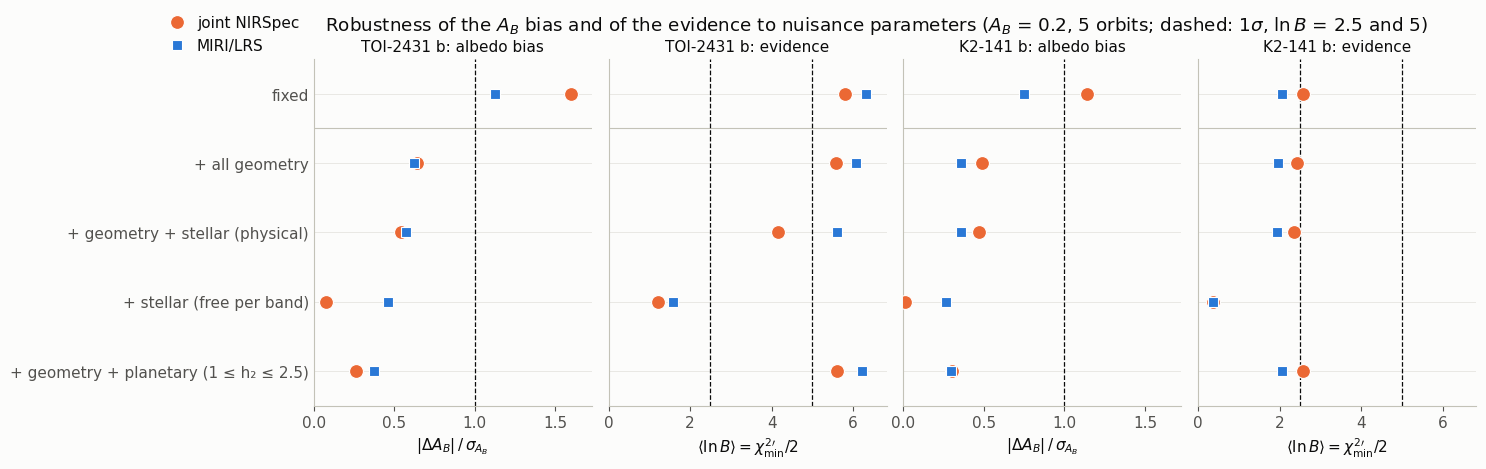

In [4]:
# Horizontal dot plot of the headline rows (FIGURE_ROWS) in the primary modes (FIGURE_MODES): one line per row, the modes as markers on the same line, so a row reads left to right
ypos = {r: k for k, r in enumerate(FIGURE_ROWS)}
METRICS = (("bias_sigma", r"$|\Delta A_B|\,/\,\sigma_{A_B}$", "albedo bias", (1.,)), ("lnB_mean", r"$\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$", "evidence", (2.5, 5.)))
STYLE = dict(zip(MODES, zip((C_HI, C_REDIST, INK_2), "osD", (10, 6.5, 6.5))))   # colour, marker, size: the square fits inside the circle, so coinciding points stay visible
xmax = {col: 1.08 * max(TABLES[(name, m)].set_index("row").loc[FIGURE_ROWS, col].max() for name in PLANETS for m in FIGURE_MODES) for col, *_ in METRICS}   # one x scale per quantity

fig, axs = plt.subplots(1, 2 * len(PLANETS), figsize=(15., 0.5 * len(FIGURE_ROWS) + 2.), sharey=True, gridspec_kw=dict(wspace=0.06))
for j, name in enumerate(PLANETS):
    for m, (col, xlabel, what, refs) in enumerate(METRICS):
        ax = axs[2 * j + m]
        ax.grid(False)
        for yy in ypos.values(): ax.axhline(yy, color="#e6e5e0", lw=0.6, zorder=0)    # one guide line per row
        ax.axhline(0.5, color=AXIS, lw=0.8, zorder=0)                                  # the reference row apart from the rest
        for v in refs: ax.axvline(v, color=INK, lw=0.9, ls="--", zorder=1)
        for mode in FIGURE_MODES:
            c, mk, ms = STYLE[mode]
            t = TABLES[(name, mode)].set_index("row")
            ax.plot([t.loc[r, col] for r in FIGURE_ROWS], list(ypos.values()), mk, ls="none", color=c, ms=ms, mec="white", mew=0.8, zorder=3, label=mode)
        ax.set_xlim(0., xmax[col]); ax.set_xlabel(xlabel); ax.set_title(f"{name}: {what}", fontsize=11)
axs[0].set_ylim(len(FIGURE_ROWS) - 0.5, -0.5)
axs[0].set_yticks(list(ypos.values()), FIGURE_ROWS)
for ax in axs: ax.tick_params(axis="y", length=0)   # the rows are labelled on the left only
axs[0].legend(loc="lower right", bbox_to_anchor=(-0.03, 1.), borderaxespad=0., handletextpad=0.3)   # above the row labels, where it stays clear of the data
fig.suptitle(rf"Robustness of the $A_B$ bias and of the evidence to nuisance parameters ($A_B$ = {A_B_true:g}, {n_orbits} orbits; dashed: $1\sigma$, $\ln B$ = 2.5 and 5)")
plt.show()

## 2. Why the ellipsoidal terms absorb the evidence

The whitened residual of the point-source model before ($r_0$, at the true $A_B$) and after ($r_\perp$) the $A_B$ fit, against each ellipsoidal term fitted alone with $A_B$ and the baseline. To first order $|r_0|^2 = (\Delta A_B/\sigma_{A_B})^2 + \chi^2_{\min}$: the part that looks like an albedo change becomes the bias, the rest the evidence. Inside the occultation $r_\perp$ is only the fitted baseline, with the sign of $-\cos 4\pi\phi$, so the stellar term matches it there too; the planetary term is zero there and overlaps with the albedo response outside.

The second figure shows what each fit removes from $r_\perp$; the printed $\chi^{2\prime}_{\min}/\chi^2_{\min}$ is the share that remains, the cosines the overlap of residuals and columns.

TOI-2431 b, joint NIRSpec: cos(r_perp, stellar) = +0.77, cos(r_perp, planetary) = +0.34, cos(stellar, planetary) = +0.76, cos(j_A, stellar) = -0.45, cos(j_A, planetary) = -0.84
   |r_0|^2 = 14.22 = chi2_min 11.58 + albedo-like part 2.64 (linear: (dA_B |j_A|)^2 = 2.56);  cos(r_0, j_A) = -0.43, cos(r_0, stellar) = +0.89, cos(r_0, planetary) = +0.67
   chi2'_min / chi2_min (what remains, prior penalty included): stellar ellipsoidal, physical prior 0.73, stellar ellipsoidal, free per band 0.21, planetary deformation 0.61
TOI-2431 b, MIRI/LRS: cos(r_perp, stellar) = +0.76, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.78, cos(j_A, stellar) = -0.47, cos(j_A, planetary) = -0.84
   |r_0|^2 = 13.97 = chi2_min 12.64 + albedo-like part 1.33 (linear: (dA_B |j_A|)^2 = 1.27);  cos(r_0, j_A) = -0.31, cos(r_0, stellar) = +0.87, cos(r_0, planetary) = +0.58
   chi2'_min / chi2_min (what remains, prior penalty included): stellar ellipsoidal, physical prior 0.91, stellar ellipsoidal, free p

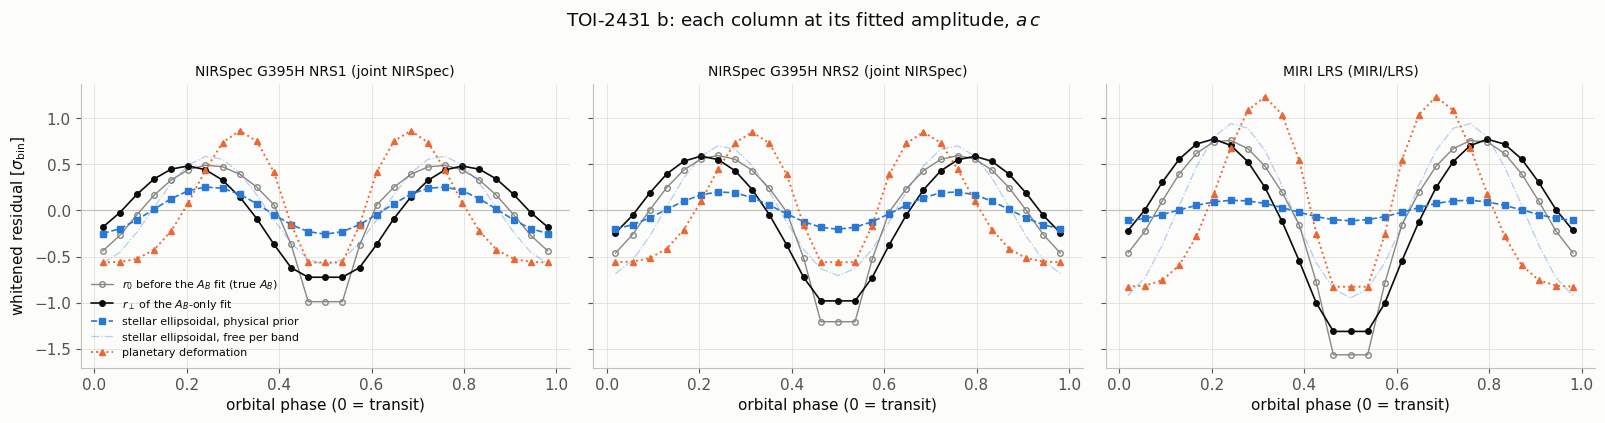

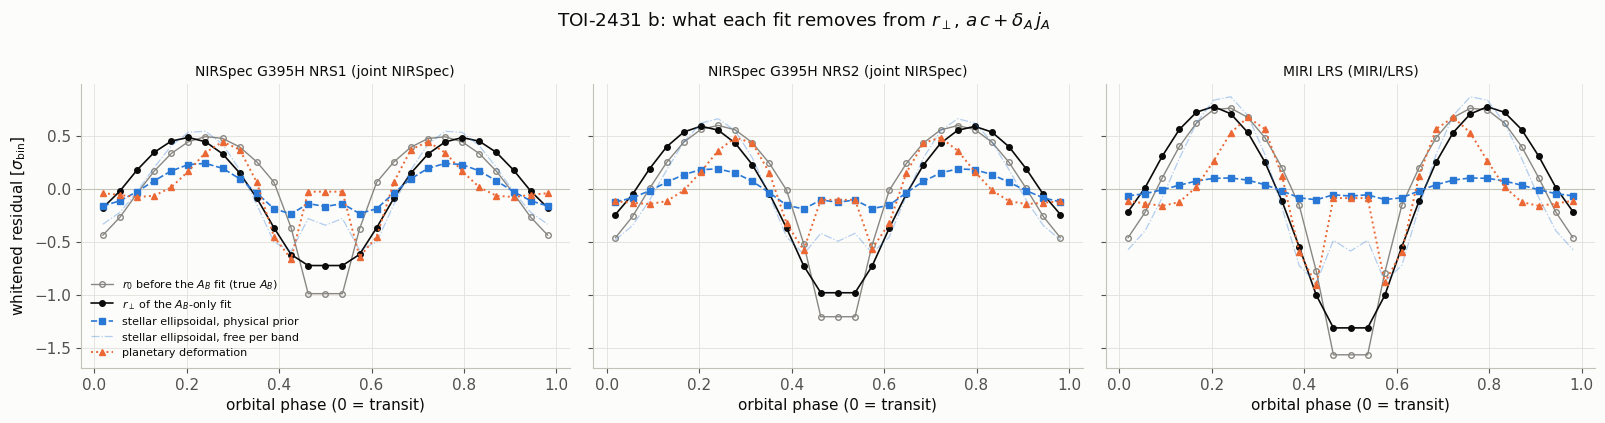

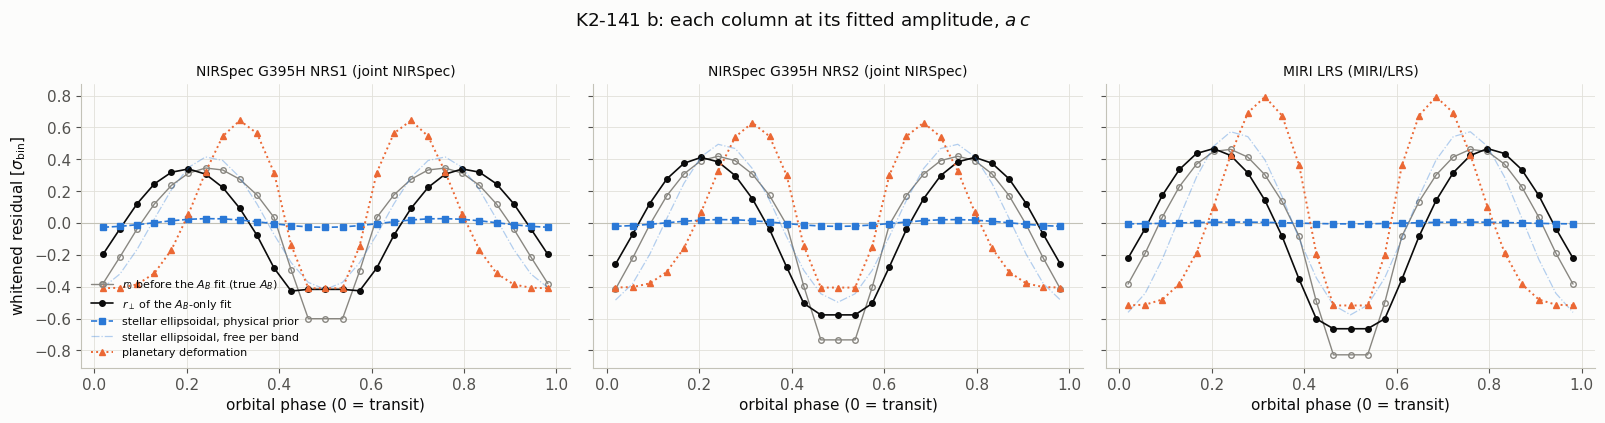

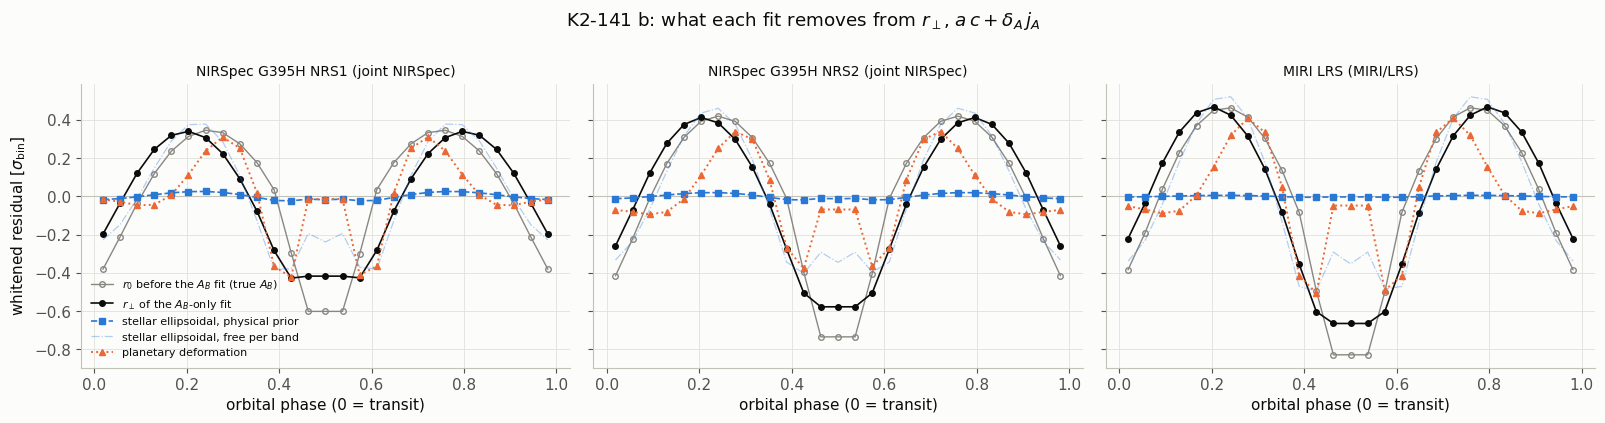

In [5]:
cosang = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))

def residual_at_truth(name, mode):
    '''Whitened residual of the point-source model at the TRUE A_B (before the A_B fit), baseline removed per detector like r_perp.'''
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return evidence_residual(c, truth, A_B_fit=A_B_true, **kw)["r_perp"]

FIG_CASES = [(name, mode) for name in PLANETS for mode in MODES if not mode.startswith("NIRSpec +")]   # the three-detector set repeats the same blocks
R0 = dict(zip(FIG_CASES, pmap(residual_at_truth, FIG_CASES)))

# The ellipsoidal terms, each fitted alone with A_B and the baseline: the stellar term with the physical prior and the planetary term as in the table; the free stellar term
# (the worst case, still a headline row) faint
TERMS = {"stellar ellipsoidal, physical prior": (("stellar_shared",), dict(marker="s", ls="--", color=C_REDIST, lw=1.2, ms=4)),
         "stellar ellipsoidal, free per band":  (("stellar",), dict(ls="-.", color=C_REDIST, lw=0.9, alpha=0.35)),
         "planetary deformation":               (("planetary",), dict(marker="^", ls=":", color=C_HI, lw=1.4, ms=4))}
# Two figures per planet: each column at its fitted amplitude (a c), and what each fit removes from r_perp (a c + delta_A j_A = r_perp - r_fit, so the gap to r_perp is what remains)
QUANTITIES = {"columns": (r"each column at its fitted amplitude, $a\,c$", lambda p, s: sum(s["delta"][n] * p["columns"][n] for n in s["names"])),
              "removed": (r"what each fit removes from $r_\perp$, $a\,c + \delta_A\,j_A$", lambda p, s: p["y"] - s["r_perp"])}

SOLS = {}
for name, mode in FIG_CASES:
    p, r0 = PROBLEMS[(name, mode)], R0[(name, mode)]
    SOLS[(name, mode)] = {label: nuisance_solve(p, nuis) for label, (nuis, _) in TERMS.items()}
    stellar_all = np.sum([p["columns"][n] for n in SOLS[(name, mode)]["stellar ellipsoidal, free per band"]["names"]], axis=0)   # all detectors with one amplitude, for the angles
    print(f"{name}, {mode}: cos(r_perp, stellar) = {cosang(p['y'], stellar_all):+.2f}, cos(r_perp, planetary) = {cosang(p['y'], p['columns']['planetary']):+.2f}, "
          f"cos(stellar, planetary) = {cosang(stellar_all, p['columns']['planetary']):+.2f}, cos(j_A, stellar) = {cosang(p['j_A'], stellar_all):+.2f}, cos(j_A, planetary) = {cosang(p['j_A'], p['columns']['planetary']):+.2f}")
    dA = p["A_B_fit"] - A_B_true
    print(f"   |r_0|^2 = {r0 @ r0:.2f} = chi2_min {p['chi2']:.2f} + albedo-like part {r0 @ r0 - p['chi2']:.2f} (linear: (dA_B |j_A|)^2 = {(dA * np.linalg.norm(p['j_A'])) ** 2:.2f});  "
          f"cos(r_0, j_A) = {cosang(r0, p['j_A']):+.2f}, cos(r_0, stellar) = {cosang(r0, stellar_all):+.2f}, cos(r_0, planetary) = {cosang(r0, p['columns']['planetary']):+.2f}")
    print("   chi2'_min / chi2_min (what remains, prior penalty included): " + ", ".join(f"{label} {s['chi2'] / p['chi2']:.2f}" for label, s in SOLS[(name, mode)].items()))

for name in PLANETS:
    modes = [m for (n, m) in FIG_CASES if n == name]
    ncol = sum(len(PROBLEMS[(name, m)]["blocks"]) for m in modes)
    for key, (what, curve) in QUANTITIES.items():
        fig, axs = plt.subplots(1, ncol, figsize=(5.4 * ncol, 4.2), sharey=True, squeeze=False)
        k = 0
        for mode in modes:
            p, r0 = PROBLEMS[(name, mode)], R0[(name, mode)]
            curves = {label: curve(p, s) for label, s in SOLS[(name, mode)].items()}
            for blk, det in zip(p["blocks"], detectors(MODES[mode])):
                ax = axs[0, k]; k += 1
                ph = p["phase"][blk]
                ax.axhline(0., color=AXIS, lw=.8)
                ax.plot(ph, r0[blk], "o-", color=MUTED, mfc="none", lw=1.0, ms=4, label=r"$r_0$ before the $A_B$ fit (true $A_B$)")
                ax.plot(ph, p["y"][blk], "o-", color=INK, lw=1.2, ms=4, label=r"$r_\perp$ of the $A_B$-only fit")
                for label, (_, style) in TERMS.items():
                    ax.plot(ph, curves[label][blk], label=label, **style)
                ax.set_title(f"{instrument_label(det, oneline=True)} ({mode})", fontsize=10); ax.set_xlabel("orbital phase (0 = transit)")
        axs[0, 0].set_ylabel(r"whitened residual [$\sigma_{\rm bin}$]"); axs[0, 0].legend(fontsize=8)
        fig.suptitle(f"{name}: {what}", y=1.0)
        fig.tight_layout()
        plt.show()

## 3. The ellipsoidal terms: physical amplitudes and the prior of the stellar term

**Star.** $A_{\rm ell} = \alpha_{\rm ell}\,(M_p/M_\star)\,(R_\star/a)^3\sin^2 i$ with $\alpha_{\rm ell} = 0.15\,(15 + u)(1 + g)/(3 - u)$ (Morris & Naftilan 1993; Shporer 2017), $u$ and $g$ the band's limb- and gravity-darkening coefficients. $\alpha_{\rm ell}$ varies by less than about 10 % over 3–10 µm, so one amplitude serves all detectors (`stellar_shared`); its prior (`ellipsoidal_prior`) adds the published errors of mass ratio and geometry and a $(u, g)$ bracket in quadrature.

**Planet.** The fitted elongation $\delta = (a_1 - a_2)/a_2$ ($a_1$ the semi-axis toward the star, $a_2$ the one along the orbit, $a_3$ the polar one; $\xi$ in the paper) against the published $(a_1 - a_3)/a_1$ of TOI-2431 b (Taş et al. 2026, $h_2 = 1$), with $a_1 - a_2 = \tfrac34(a_1 - a_3)$ in tidal equilibrium.

The table goes from no stellar term over a free amplitude per band and a shared one without prior to the shared one with the physical prior, then scales the prior width (`PRIOR_SCALES`) and shifts the last band ratio (`RATIO_SHIFT`).

In [6]:
AXIS_RATIO = {"TOI-2431 b": (0.087, 0.017)}  # (a1 - a3) / a1 for h2 = 1: Taş et al. 2026 (A&A 707, A238) Sect. 6.3.1
R12_OVER_R13 = 0.75                          # (a1 - a2) / (a1 - a3) of a synchronously rotating body in tidal equilibrium (see above): the planetary amplitude compares with (a1 - a2) / a1
PRIOR_SCALES = (0.5, 2.)                     # sensitivity check: the prior width of the shared stellar amplitude times these
RATIO_SHIFT = 0.15                           # sensitivity check: the band ratio of the last detector of a multi-detector mode changed by this fraction

for name in PLANETS:
    e, (q, fq) = ELLIPSOIDAL[name], mass_ratio(name)
    print(f"{name}: M_p / M_star = {q:.3e} (+- {100 * fq:.0f} %)  ->  expected stellar ellipsoidal semi-amplitude {e['A']:.2f} ppm (u in {U_RANGE}, g in {G_RANGE});  "
          f"prior sigma {e['sigma']:.2f} ppm = {100 * e['frac']:.0f} % (" + ", ".join(f"{k} {100 * v:.0f} %" for k, v in e["parts"].items()) + ")")
    if name in AXIS_RATIO: print(f"   published tidal deformation (h2 = 1): (a1 - a3)/a1 = {AXIS_RATIO[name][0]:.3f} +- {AXIS_RATIO[name][1]:.3f}  ->  (a1 - a2)/a1 = {R12_OVER_R13 * AXIS_RATIO[name][0]:.3f} +- {R12_OVER_R13 * AXIS_RATIO[name][1]:.3f}, the scale of the planetary amplitude")
    rows = []
    for mode in MODES:
        p = PROBLEMS[(name, mode)]
        flat = {**p, "priors": {k: v for k, v in p["priors"].items() if k != "stellar_shared"}}
        variants = {"none": (p, ()), "free per band": (p, ("stellar",)), "shared, flat": (flat, ("stellar_shared",)), "shared, physical prior": (p, ("stellar_shared",))}
        for f in PRIOR_SCALES:
            variants[f"shared, prior x {f:g}"] = ({**p, "priors": {**p["priors"], "stellar_shared": f * p["priors"]["stellar_shared"]}}, ("stellar_shared",))
        if len(p["blocks"]) > 1:
            for f in (1. - RATIO_SHIFT, 1. + RATIO_SHIFT):
                r = p["stellar_ratios"].copy(); r[-1] *= f
                variants[f"shared, last band ratio x {f:g}"] = ({**p, "columns": {**p["columns"], "stellar_shared": stellar_shared_column(p["columns"], r)}}, ("stellar_shared",))
        for label, (pp, nuis) in variants.items():
            s = nuisance_solve(pp, nuis)
            rows.append({"mode": mode, "stellar term": label, "sigma_A_B": s["sigma_A_B"], "bias_sigma": abs(s["A_B_fit"] - A_B_true) / s["sigma_A_B"], "lnB_mean": s["lnB_mean"],
                         "amplitude [ppm]": ", ".join(f"{s['delta'][n]:.1f} +- {s['sigma_post'][n]:.1f}" for n in s["names"]) or "-"})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
    print("   planetary amplitude fitted alone: " + ";  ".join(f"{m} {TABLES[(name, m)].set_index('row').loc['+ planetary (free amplitude)', 'planetary']:.3f} +- {TABLES[(name, m)].set_index('row').loc['+ planetary (free amplitude)', 'sig planetary']:.3f}" for m in MODES), "\n")

TOI-2431 b: M_p / M_star = 2.817e-05 (+- 26 %)  ->  expected stellar ellipsoidal semi-amplitude 2.96 ppm (u in (0.1, 0.3), g in (0.1, 0.4));  prior sigma 0.92 ppm = 31 % (M_p / M_star 26 %, (R_star / a)^3 6 %, sin^2 i 1 %, alpha_ell (u, g) 16 %)
   published tidal deformation (h2 = 1): (a1 - a3)/a1 = 0.087 +- 0.017  ->  (a1 - a2)/a1 = 0.065 +- 0.013, the scale of the planetary amplitude
         mode                   stellar term  sigma_A_B  bias_sigma  lnB_mean                    amplitude [ppm]
joint NIRSpec                           none     0.0266         1.6      5.79                                  -
joint NIRSpec                  free per band     0.0298      0.0749      1.21             3.0 +- 1.5, 4.6 +- 1.8
joint NIRSpec                   shared, flat     0.0298       0.089      1.45                         3.6 +- 1.2
joint NIRSpec         shared, physical prior     0.0278        1.01      4.21                         1.3 +- 0.7
joint NIRSpec            shared, prior x 0.5 

## 4. Checks

The linear rows against full nonlinear least-squares fits (`nuisance_fit_nonlinear`; priors as residual rows) for the cases of `NL_CHECKS`: $\hat A_B$, $\sigma_{A_B}$ and $\chi^2_{\min}$. Where a nuisance shifts $A_B$ by more than its $\sigma$ the response to $A_B$ turns nonlinear ($T \propto (1-A_B)^{1/4}$), so $\hat A_B$ and $\sigma_{A_B}$ can differ while $\chi^2_{\min}$ stays close.

In [7]:
# The linear rows against nonlinear least-squares fits: every row of interest for TOI-2431 b in MIRI/LRS, and for the joint NIRSpec fit the geometry and stellar rows (b, the shared and the per-band stellar term)
NL_CHECKS = {("TOI-2431 b", "MIRI/LRS"): ["+ all geometry", "+ stellar (physical)", "+ geometry + stellar (physical)", "+ stellar (free per band)", "+ planetary (free amplitude)", "+ geometry + planetary (free amplitude)"],
             ("TOI-2431 b", "joint NIRSpec"): ["+ all geometry", "+ stellar (physical)", "+ geometry + stellar (physical)", "+ stellar (free per band)"]}
NL_JOBS = [(key, label) for key, labels in NL_CHECKS.items() for label in labels]

def nonlinear(key, label):
    name, mode = key
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, ROWS[name][label], priors=PROBLEMS[key]["priors"], stellar_ratios=STELLAR_RATIOS, **kw)

NL = dict(zip(NL_JOBS, pmap(nonlinear, NL_JOBS)))
for key, labels in NL_CHECKS.items():
    p = PROBLEMS[key]
    lin = {label: nuisance_solve(p, ROWS[key[0]][label]) for label in labels}
    print(f"{key[0]}, {key[1]}: linear rows against the nonlinear least-squares fit")
    print(pd.DataFrame([{"row": label, "A_B lin": lin[label]["A_B_fit"], "A_B nonlin": NL[(key, label)]["A_B_fit"], "sigma lin": lin[label]["sigma_A_B"], "sigma nonlin": NL[(key, label)]["sigma_A_B"],
                         "chi2 lin": lin[label]["chi2"], "chi2 nonlin": NL[(key, label)]["chi2"], "nfev": NL[(key, label)]["nfev"]} for label in labels]).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    print("fitted nuisances, linear | nonlinear (value +- sigma):")
    for label in labels:
        nl = NL[(key, label)]
        print(f"   {label}: " + ";  ".join(f"{n} {p['values'].get(n, 0.) + lin[label]['delta'][n]:.5g} +- {lin[label]['sigma_post'][n]:.2g} | {nl['values'][n]:.5g} +- {nl['sigma_post'][n]:.2g}" for n in lin[label]["names"]))
    print()

TOI-2431 b, MIRI/LRS: linear rows against the nonlinear least-squares fit
                                    row  A_B lin  A_B nonlin  sigma lin  sigma nonlin  chi2 lin  chi2 nonlin  nfev
                         + all geometry   0.1516      0.1507    0.07747        0.0767     12.17        12.17    16
                   + stellar (physical)   0.1505      0.1505    0.05397       0.05351     11.53        11.53    16
        + geometry + stellar (physical)   0.1557      0.1558    0.07758       0.07649      11.2         11.2    16
              + stellar (free per band)   0.2277      0.2246    0.06022       0.05591     3.172        3.172    14
           + planetary (free amplitude)   0.3187      0.3112    0.09765       0.08885     7.892        7.927    18
+ geometry + planetary (free amplitude)   0.3268      0.3184     0.1144        0.1009     7.837        7.867    21
fitted nuisances, linear | nonlinear (value +- sigma):
   + all geometry: a_rs|b 2.0691 +- 0.03 | 2.069 +- 0.03;  rp_rs 0

## 5. Both point-source fits with the same nuisances

The fit with redistribution, linearised around its own noiseless solution $(\hat A_B, \hat F > 0)$ (`nuisance_problem(..., redist=True)`, extra column $j_F$), since the $A_B$-only fit sits at its $F = 0$ edge. `nuisance_both_fits` gives per row of `ROWS_BOTH` (the deformation with $h_2$ flat over its range, as in section 1) the bias, $\sigma_{A_B}$ and $\langle\ln B\rangle$ of the $A_B$-only fit and, for the fit with redistribution (suffix `_J`), $\hat F$ and
$$z_F' = \sqrt{\chi^{2\prime}_{\min}(A_B, \nu) - \chi^{2\prime}_{\min}(A_B, F, \nu)},$$
the significance of the spurious $F$ when both fits carry the nuisances $\nu$. The second table gives where each fit moves the geometry; the check compares the free-geometry row with a nonlinear fit.

In [8]:
# The fit with redistribution as a linear problem around its own noiseless solution (nuisance_problem(..., redist=True)), paired with the A_B-only problems of section 1
def case_redist(name, mode):
    '''case() for the fit with redistribution: the nuisance problem around its noiseless solution (A_B_fit, F_fit).'''
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, redist=True, **kw)

KEYS = [(name, mode) for name in PLANETS for mode in FIGURE_MODES]
RPROBLEMS = dict(zip(KEYS, pmap(case_redist, KEYS)))

def both_fits(key, nuisances=(), priors=None, time_factor=1., limits=None, uniform=None):
    '''Both point-source fits of one case (planet, mode) with the same nuisances (nuisance_both_fits).'''
    return nuisance_both_fits(PROBLEMS[key], RPROBLEMS[key], A_B_true, nuisances, priors, time_factor, limits, uniform)

def rows_both(name):
    geom = ROWS[name]["+ all geometry"]
    return {"fixed geometry": dict(), "free geometry": dict(nuisances=geom), "free geometry + stellar (physical)": dict(nuisances=(*geom, "stellar_shared")),
            "free geometry + stellar (free per band)": dict(nuisances=(*geom, "stellar")), f"free geometry + planetary ({H2_RANGE})": dict(nuisances=(*geom, "planetary"), uniform=LIMITS[name])}

ROWS_BOTH = {name: rows_both(name) for name in PLANETS}
BOTH = {k: {label: both_fits(k, **spec) for label, spec in ROWS_BOTH[k[0]].items()} for k in KEYS}

HEAD_BOTH = {"bias": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩", "bias_J": "ΔA_B (F)", "bias_sigma_J": "|ΔA_B|/σ (F)", "F_fit": "F", "z_F": "z_F"}
for name in PLANETS:
    summary = pd.concat({mode: pd.DataFrame({label: {HEAD_BOTH[c]: b[c] for c in HEAD_BOTH} for label, b in BOTH[(name, mode)].items()}).T for mode in FIGURE_MODES}, axis=1)
    display(summary.style.format("{:.3g}").set_caption(f"{name}: the A_B-only fit (ΔA_B, |ΔA_B|/σ, ⟨ln B⟩) and the fit with redistribution (F) with the same nuisances"))
    shifts = pd.DataFrame({mode: {fit: " · ".join(f"{SHORT[n]} {BOTH[(name, mode)]['free geometry'][key]['delta'][n] / PROBLEMS[(name, mode)]['priors'][n]:+.2f}" for n in ROWS[name]["+ all geometry"])
                                  for fit, key in (("A_B-only", "fit"), ("with redistribution", "fit_J"))} for mode in FIGURE_MODES})
    display(shifts.style.set_caption(f"{name}, free geometry: shift of each geometry parameter in units of its prior σ"))

,joint NIRSpec,MIRI/LRS
A_B-only,a/R* -0.28 · Rp/R* +0.06 · b +0.19,a/R* -0.27 · Rp/R* -0.01 · b +0.07
with redistribution,a/R* -0.07 · Rp/R* +0.24 · b +0.02,a/R* -0.06 · Rp/R* +0.48 · b -0.08


,joint NIRSpec,MIRI/LRS
A_B-only,a/R* -0.10 · Rp/R* +0.06 · i -0.10,a/R* -0.13 · Rp/R* +0.04 · i -0.01
with redistribution,a/R* -0.03 · Rp/R* +0.17 · i -0.03,a/R* -0.05 · Rp/R* +0.34 · i +0.02


In [9]:
# Check of the free-geometry row of the fit with redistribution: nonlinear least squares over (A_B, F, geometry), started at the noiseless joint fit (F > 0, away from the F = 0 edge)
def nonlinear_redist(name, mode):
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, ROWS[name]["+ all geometry"], priors=PROBLEMS[(name, mode)]["priors"], stellar_ratios=STELLAR_RATIOS, redist=True, **kw)

NL_F = dict(zip(KEYS, pmap(nonlinear_redist, KEYS)))
print("fit with redistribution, free geometry: linear row | nonlinear least squares")
for k in KEYS:
    lin, nl = BOTH[k]["free geometry"]["fit_J"], NL_F[k]
    print(f"   {k[0]:11s} {k[1]:14s} A_B {lin['A_B_fit']:.4f} | {nl['A_B_fit']:.4f};  F {lin['F_fit']:.4f} | {nl['F_fit']:.4f};  sigma_A_B {lin['sigma_A_B']:.4f} | {nl['sigma_A_B']:.4f};  chi2 {lin['chi2']:.3f} | {nl['chi2']:.3f}")

fit with redistribution, free geometry: linear row | nonlinear least squares
   TOI-2431 b  joint NIRSpec  A_B 0.1297 | 0.1289;  F 0.0168 | 0.0171;  sigma_A_B 0.0468 | 0.0456;  chi2 3.521 | 3.508
   TOI-2431 b  MIRI/LRS       A_B 0.0906 | 0.0883;  F 0.0076 | 0.0078;  sigma_A_B 0.0881 | 0.0827;  chi2 2.298 | 2.301
   K2-141 b    joint NIRSpec  A_B 0.1407 | 0.1394;  F 0.0126 | 0.0129;  sigma_A_B 0.0581 | 0.0566;  chi2 1.804 | 1.792
   K2-141 b    MIRI/LRS       A_B 0.1064 | 0.1038;  F 0.0054 | 0.0056;  sigma_A_B 0.1324 | 0.1238;  chi2 0.924 | 0.922


**Figure.** The rows of `ROWS_BOTH` for both fits in the two primary modes, one line of panels per planet: the significance of the albedo bias, $z_F$ and the expected evidence. Grey circles: $A_B$-only; blue squares: with redistribution; filled: joint NIRSpec, open: MIRI/LRS. Dashed: $1\sigma$, $z_F = 2$ and the evidence thresholds 2.5 and 5.

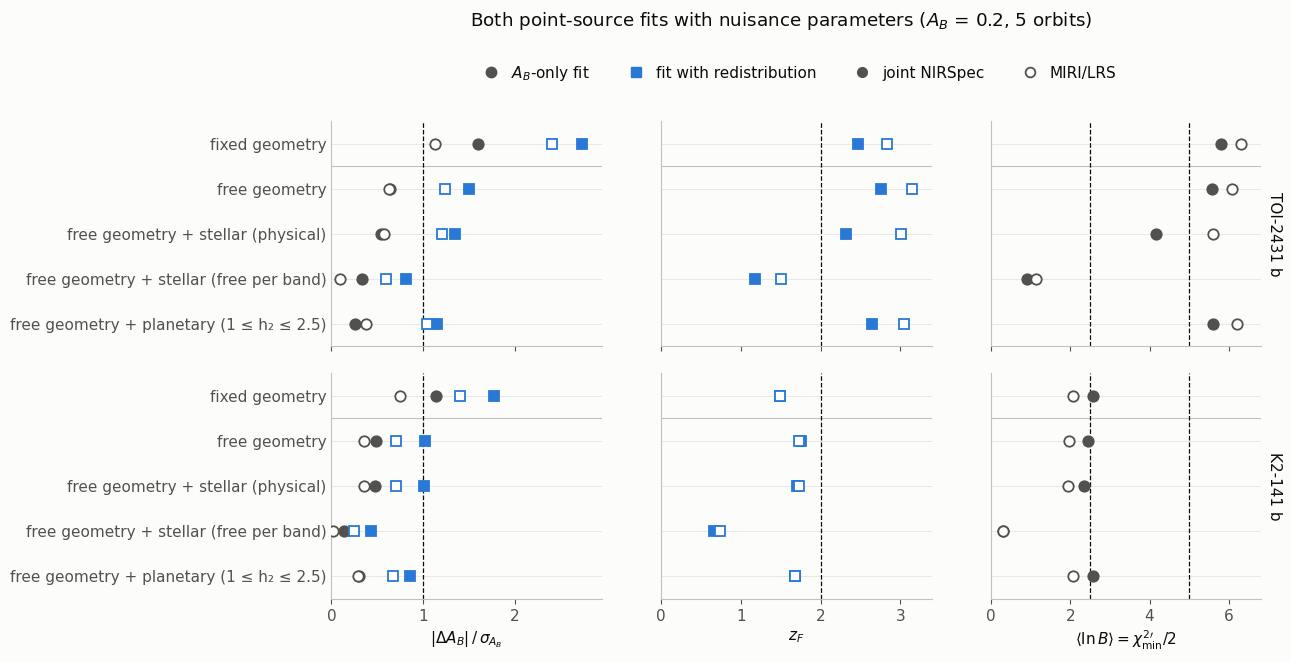

In [10]:
# Dot plot of ROWS_BOTH: per planet the albedo bias of both fits, z_F and <ln B>; colour and symbol = fit (as in the retrieval figures), filled = joint NIRSpec, open = MIRI/LRS
rows_fig = list(ROWS_BOTH[PLANETS[0]])
ypos = np.arange(len(rows_fig))
PANELS = ((r"$|\Delta A_B|\,/\,\sigma_{A_B}$", (("bias_sigma", C_NAIVE, "o"), ("bias_sigma_J", C_REDIST, "s")), (1.,)), (r"$z_F$", (("z_F", C_REDIST, "s"),), (2.,)),
          (r"$\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$", (("lnB_mean", C_NAIVE, "o"),), (2.5, 5.)))
FILL = dict(zip(FIGURE_MODES, (True, False)))
xmax = [1.08 * max(BOTH[k][r][col] for k in KEYS for r in rows_fig for col, *_ in cols) for _, cols, _ in PANELS]   # one x scale per quantity

fig, axs = plt.subplots(len(PLANETS), len(PANELS), figsize=(12., 1.1 + 0.42 * len(rows_fig) * len(PLANETS) + 0.9), sharey=True, sharex="col", squeeze=False, gridspec_kw=dict(wspace=0.22, hspace=0.12))
for i, name in enumerate(PLANETS):
    for j, (xlabel, cols, refs) in enumerate(PANELS):
        ax = axs[i, j]
        ax.grid(False)
        for yy in ypos: ax.axhline(yy, color="#e6e5e0", lw=0.6, zorder=0)
        ax.axhline(0.5, color=AXIS, lw=0.8, zorder=0)   # the fixed-geometry row apart from the rest
        for v in refs: ax.axvline(v, color=INK, lw=0.9, ls="--", zorder=1)
        for mode in FIGURE_MODES:
            for col, colour, marker in cols:
                ax.plot([BOTH[(name, mode)][r][col] for r in rows_fig], ypos, marker, ls="none", color=colour, mfc=colour if FILL[mode] else "white", ms=7.5 if marker == "o" else 6.5, mew=1.3, zorder=3)
        ax.set_xlim(0., xmax[j])
        if i == len(PLANETS) - 1: ax.set_xlabel(xlabel)
    axs[i, 0].set_yticks(ypos, rows_fig)
    axs[i, -1].annotate(name, (1.02, 0.5), xycoords="axes fraction", rotation=270, va="center", fontsize=11)
axs[0, 0].set_ylim(len(rows_fig) - 0.5, -0.5)
for ax in axs.ravel(): ax.tick_params(axis="y", length=0)
handles = [plt.Line2D([], [], marker="o", ls="none", color=C_NAIVE, ms=7.5, label=r"$A_B$-only fit"), plt.Line2D([], [], marker="s", ls="none", color=C_REDIST, ms=6.5, label="fit with redistribution"),
           plt.Line2D([], [], marker="o", ls="none", color=INK_2, ms=7, label=FIGURE_MODES[0]), plt.Line2D([], [], marker="o", ls="none", color=INK_2, mfc="white", ms=7, mew=1.3, label=FIGURE_MODES[1])]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5 * (axs[0, 0].get_position().x0 + axs[0, -1].get_position().x1), 0.995), handletextpad=0.3)   # centred on the panels
fig.suptitle(rf"Both point-source fits with nuisance parameters ($A_B$ = {A_B_true:g}, {n_orbits} orbits)", y=1.06)
plt.show()

## 6. Further nuisances and checks

- **Stellar $T_{\rm eff}$** (column `T_s`, at fixed log g and [Fe/H]), with the Gaussian prior `SIGMA_TEFF`: the published error and, for TOI-2431 b, whose published error is much smaller, a systematic floor of about 2 % (Tayar et al. 2022); the published 79 K of K2-141 b is already close to that floor.
- **Planetary deformation within its physical range** $1 \leq h_2 \leq 2.5$, with $\delta = 1.5\,h_2\,(M_\star/M_p)(R_p/a)^3$ (`deformation_amplitude`). The headline rows of sections 1 and 5 give $h_2$ a flat prior over `DEFORMATION_H2_RANGE` for a planet with $h_2$ = `DEFORMATION_H2_TRUE` (exact for the linear problem, `bounded_posterior`): the bias is the difference of the two models' posterior medians of $A_B$, and $\langle\ln B\rangle = \chi^{2\prime}_{\rm free}/2 + \ln(m_{\rm ext}/m_{\rm ps})$ with $m$ each model's likelihood share within the range. Here also, for comparison: the best fit within the range (`limits`), a Gaussian prior of the same width and the free amplitude.
- **Binning**: the headline rows with `N_BINS_CHECK` bins per orbit, since the baseline binning does not resolve the transit.

In [11]:
SIGMA_TEFF = {"TOI-2431 b": (28., 80.),   # [K] Taş et al. 2026: T_eff = 4109 +- 28 K (formal), and a 2 % systematic floor
              "K2-141 b": (79.,)}          # [K] Malavolta et al. 2018: 4599 +- 79 K
N_BINS_CHECK = 135

show = lambda b: {head: b[c] for c, head in {"sigma": "σ_AB", "bias": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩", "bias_J": "ΔA_B (F)", "bias_sigma_J": "|ΔA_B|/σ (F)", "z_F": "z_F"}.items()}
for k in KEYS:
    geom, deform = ROWS[k[0]]["+ all geometry"], DEFORMATION[k[0]]
    rows = {"fixed geometry": show(both_fits(k)), "free geometry": show(both_fits(k, geom))}
    for s in SIGMA_TEFF[k[0]]: rows[f"free geometry + T_eff ({s:g} K)"] = show(both_fits(k, (*geom, "T_s"), {"T_s": s}))
    uni = nuisance_both_fits(PROBLEMS[k], RPROBLEMS[k], A_B_true, (*geom, "planetary"), uniform=LIMITS[k[0]])   # flat prior over the range: the headline row of sections 1 and 5
    rows[f"free geometry + planetary (flat prior, {H2_RANGE}, true h2 = {DEFORMATION_H2_TRUE:g})"] = show(uni)
    rows["free geometry + planetary (best fit within the same range)"] = show(both_fits(k, (*geom, "planetary"), limits=LIMITS[k[0]]))
    rows["free geometry + planetary (Gaussian prior)"] = show(both_fits(k, (*geom, "planetary"), {"planetary": deform["sigma"]}))
    rows["free geometry + planetary (free)"] = show(both_fits(k, (*geom, "planetary")))
    free, lim = both_fits(k, (*geom, "planetary"))["fit"], LIMITS[k[0]]["planetary"]
    print(f"{k[0]}, {k[1]}  (planetary amplitude for h2 = 1 to 2.5: {deform['lo']:.3f} to {deform['hi']:.3f}; limits of its shift from h2 = {DEFORMATION_H2_TRUE:g}: {lim[0]:+.3f} to {lim[1]:+.3f}; sigma of the Gaussian prior {deform['sigma']:.3f}; "
          f"a free amplitude takes {free['delta']['planetary']:.3f} +- {free['sigma_post']['planetary']:.3f} on top of the true one)")
    print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3g}"))
    po = uni["posterior"]
    print(f"   flat prior: posterior shift of the deformation {po['ps']['x_mean']:+.4f} +- {po['ps']['x_sd']:.4f} (point source) and {po['ext']['x_mean']:+.4f} +- {po['ext']['x_sd']:.4f} (extended source); "
          f"share of the likelihood within the range {po['ps']['mass']:.3f} and {po['ext']['mass']:.3f}; posterior medians of A_B {uni['fit']['A_B_fit']:.4f} and {po['ext']['median'][0]:.4f}\n")

# --- binning: the headline rows of the A_B-only fit at N_BINS_CHECK bins per orbit
def case_bins(name, mode):
    c = retrieval_cfg(replace(cfg, n_bins=N_BINS_CHECK), hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, **kw)

PB = dict(zip(KEYS, pmap(case_bins, KEYS)))
print(f"{n_bins} | {N_BINS_CHECK} bins per orbit:")
for k in KEYS:
    t1, t2 = TABLES[k].set_index("row"), nuisance_table(PB[k], A_B_true, ROWS[k[0]]).set_index("row")
    print(f"   {k[0]}, {k[1]}: " + ";  ".join(f"{r}: |ΔA_B|/σ {t1.loc[r, 'bias_sigma']:.2f} | {t2.loc[r, 'bias_sigma']:.2f}, σ_AB {t1.loc[r, 'sigma_A_B']:.4f} | {t2.loc[r, 'sigma_A_B']:.4f}, ⟨ln B⟩ {t1.loc[r, 'lnB_mean']:.2f} | {t2.loc[r, 'lnB_mean']:.2f}" for r in ("fixed", "+ all geometry", "+ geometry + stellar (physical)")))

TOI-2431 b, joint NIRSpec  (planetary amplitude for h2 = 1 to 2.5: 0.057 to 0.143; limits of its shift from h2 = 2: -0.057 to +0.029; sigma of the Gaussian prior 0.025; a free amplitude takes 0.100 +- 0.049 on top of the true one)
                                                                    σ_AB     ΔA_B  |ΔA_B|/σ  ⟨ln B⟩  ΔA_B (F)  |ΔA_B|/σ (F)  z_F
fixed geometry                                                    0.0266  -0.0425       1.6    5.79   -0.0943          2.72 2.47
free geometry                                                     0.0421  -0.0269      0.64    5.57   -0.0703           1.5 2.76
free geometry + T_eff (28 K)                                      0.0424  -0.0266     0.627    5.57   -0.0698          1.48 2.76
free geometry + T_eff (80 K)                                      0.0445  -0.0243     0.547    5.55   -0.0667          1.36 2.76
free geometry + planetary (flat prior, 1 ≤ h₂ ≤ 2.5, true h2 = 2) 0.0445  -0.0116     0.262    5.61   -0.0576          1.14 